<a href="https://colab.research.google.com/github/rlawhdqn-byte/trash/blob/main/trash_classfication_5756299_%EA%B9%80%EC%A2%85%EB%B6%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. 라이브러리 임포트 및 데이터셋 다운로드

In [ ]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, ConcatDataset
import torchvision
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# 재현성을 위한 시드 고정 및 GPU 설정
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

# Kaggle 기본 데이터셋 다운로드
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
DATA_DIR = os.path.join(path, "garbage_classification")
if not os.path.exists(DATA_DIR):
    DATA_DIR = path

full_dataset = datasets.ImageFolder(root=DATA_DIR)
num_classes = len(full_dataset.classes)
print("데이터 경로:", DATA_DIR)
print(f"총 {num_classes}개 클래스:", full_dataset.classes)
print("전체 이미지 개수:", len(full_dataset), "장")

사용 장치: cuda
Using Colab cache for faster access to the 'garbage-classification' dataset.
데이터 경로: /kaggle/input/garbage-classification/garbage_classification
총 12개 클래스: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
전체 이미지 개수: 15515 장


2.[셀 2] 탐색적 데이터 분석(EDA) 및 클래스 불균형 시각화

/tmp/ipykernel_699/751716368.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")


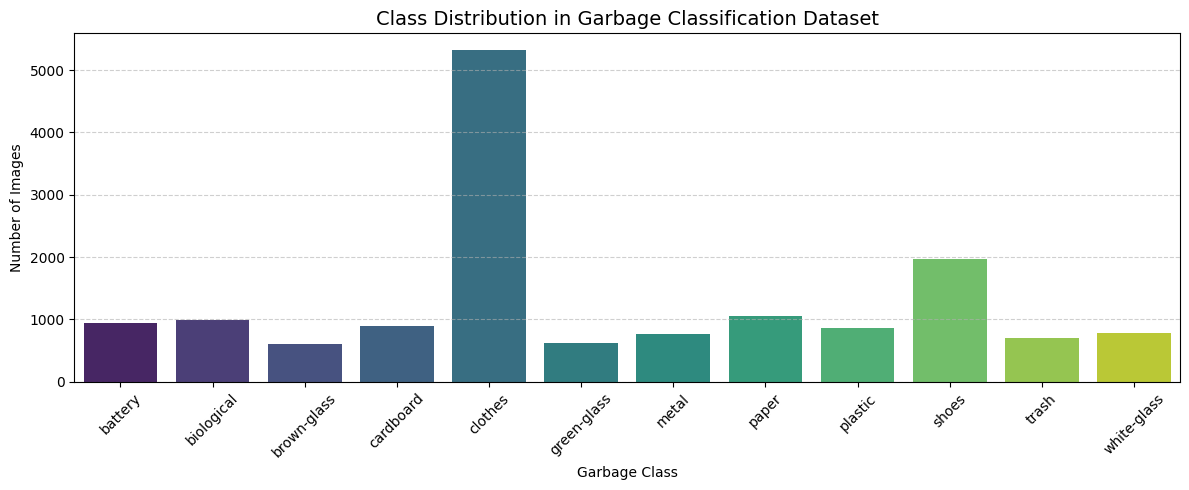

In [ ]:
class_counts = {cls: 0 for cls in full_dataset.classes}
for _, label in full_dataset.samples:
    class_counts[full_dataset.classes[label]] += 1

plt.figure(figsize=(12, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")
plt.title("Class Distribution in Garbage Classification Dataset", fontsize=14)
plt.xlabel("Garbage Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

3.데이터 분할 (Train 70% / Val 15% / Test 15%) 및 전처리 정의

In [ ]:
total_len = len(full_dataset)
train_len = int(0.7 * total_len)
val_len = int(0.15 * total_len)
test_len = total_len - train_len - val_len

train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_len, val_len, test_len],
    generator=torch.Generator().manual_seed(42)
)

class TransformedSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

fast_train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

fast_val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = TransformedSubset(train_subset, transform=fast_train_transform)
val_dataset = TransformedSubset(val_subset, transform=fast_val_transform)
test_dataset = TransformedSubset(test_subset, transform=fast_val_transform)

print(f"데이터 분할 완료 -> Train: {len(train_dataset)}장 | Val: {len(val_dataset)}장 | Test: {len(test_dataset)}장")

데이터 분할 완료 -> Train: 10860장 | Val: 2327장 | Test: 2328장


4. 순수 PyTorch 기반 커스텀 CNN(CustomGarbageCNN) 분류 모델 정의 (Dropout 규제 적용)


In [ ]:
class CustomGarbageCNN(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
        super(CustomGarbageCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1: 128x128 -> 64x64
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            # Block 2: 64x64 -> 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            # Block 3: 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            # Block 4: 16x16 -> 8x8
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.classifier(x)
        return x

def get_model(num_classes, dropout_rate=0.5):
    return CustomGarbageCNN(num_classes=num_classes, dropout_rate=dropout_rate).to(device)

5. 하이퍼파라미터 4종 비교 실험 및 학습 수행



In [ ]:
def fast_train_and_evaluate(config, epochs=15):
    train_loader = DataLoader(train_dataset, batch_size=config['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=config['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

    model = get_model(num_classes, dropout_rate=config['dropout'])
    criterion = nn.CrossEntropyLoss()

    if config['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    elif config['optimizer'] == 'SGD':
        optimizer = optim.SGD(model.parameters(), lr=config['lr'], momentum=0.9, weight_decay=config['weight_decay'])

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)
    scaler = torch.amp.GradScaler('cuda')

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_loss = running_loss / total
        train_acc = 100. * correct / total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_loss = val_loss / val_total
        val_acc = 100. * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        print(f"[{config['name']}] Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Val Loss: {val_loss:.4f}")

    model.load_state_dict(best_model_wts)
    return model, history, best_val_acc

experiments = [
    {"name": "Exp1_Adam_LR1e-3", "optimizer": "Adam", "lr": 1e-3, "batch_size": 64, "dropout": 0.3, "weight_decay": 1e-4},
    {"name": "Exp2_Adam_LR1e-4", "optimizer": "Adam", "lr": 1e-4, "batch_size": 64, "dropout": 0.5, "weight_decay": 1e-4},
    {"name": "Exp3_Adam_BS128",  "optimizer": "Adam", "lr": 1e-4, "batch_size": 128,"dropout": 0.5, "weight_decay": 1e-3},
    {"name": "Exp4_SGD_LR1e-2",  "optimizer": "SGD",  "lr": 1e-2, "batch_size": 64, "dropout": 0.5, "weight_decay": 1e-4},
]

results = {}
models_dict = {}
summary_list = []

for exp in experiments:
    print(f"\n================ {exp['name']} 시작 ================")
    trained_model, hist, best_acc = fast_train_and_evaluate(exp, epochs=15)
    results[exp['name']] = hist
    models_dict[exp['name']] = trained_model
    summary_list.append({
        "실험명": exp['name'],
        "Optimizer": exp['optimizer'],
        "Learning Rate": exp['lr'],
        "Batch Size": exp['batch_size'],
        "Dropout": exp['dropout'],
        "Weight Decay": exp['weight_decay'],
        "최고 검증 정확도(%)": round(best_acc, 2)
    })

summary_df = pd.DataFrame(summary_list)
display(summary_df)


================ Exp1_Adam_LR1e-3 시작 ================
[Exp1_Adam_LR1e-3] Epoch 1/15 | Train Acc: 47.47% | Val Acc: 56.98% | Val Loss: 1.2630
[Exp1_Adam_LR1e-3] Epoch 2/15 | Train Acc: 54.86% | Val Acc: 59.43% | Val Loss: 1.1609
[Exp1_Adam_LR1e-3] Epoch 3/15 | Train Acc: 58.06% | Val Acc: 62.61% | Val Loss: 1.1084
[Exp1_Adam_LR1e-3] Epoch 4/15 | Train Acc: 60.43% | Val Acc: 64.59% | Val Loss: 1.0288
[Exp1_Adam_LR1e-3] Epoch 5/15 | Train Acc: 62.12% | Val Acc: 65.36% | Val Loss: 1.0011
[Exp1_Adam_LR1e-3] Epoch 6/15 | Train Acc: 62.82% | Val Acc: 68.37% | Val Loss: 0.9335
[Exp1_Adam_LR1e-3] Epoch 7/15 | Train Acc: 64.59% | Val Acc: 65.19% | Val Loss: 1.0603
[Exp1_Adam_LR1e-3] Epoch 8/15 | Train Acc: 65.63% | Val Acc: 66.78% | Val Loss: 0.9652
[Exp1_Adam_LR1e-3] Epoch 9/15 | Train Acc: 67.46% | Val Acc: 71.04% | Val Loss: 0.8976
[Exp1_Adam_LR1e-3] Epoch 10/15 | Train Acc: 68.28% | Val Acc: 74.56% | Val Loss: 0.7809
[Exp1_Adam_LR1e-3] Epoch 11/15 | Train Acc: 69.39% | Val Acc: 73.31% | Val

,실험명,Optimizer,Learning Rate,Batch Size,Dropout,Weight Decay,최고 검증 정확도(%)
0,Exp1_Adam_LR1e-3,Adam,0.0010,64,0.3,0.0001,77.31
1,Exp2_Adam_LR1e-4,Adam,0.0001,64,0.5,0.0001,69.02
2,Exp3_Adam_BS128,Adam,0.0001,128,0.5,0.0010,66.74
3,Exp4_SGD_LR1e-2,SGD,0.0100,64,0.5,0.0001,68.03


6. 최적 모델 과적합(Overfitting) 점검 및 혼동 행렬(Confusion Matrix) 분석

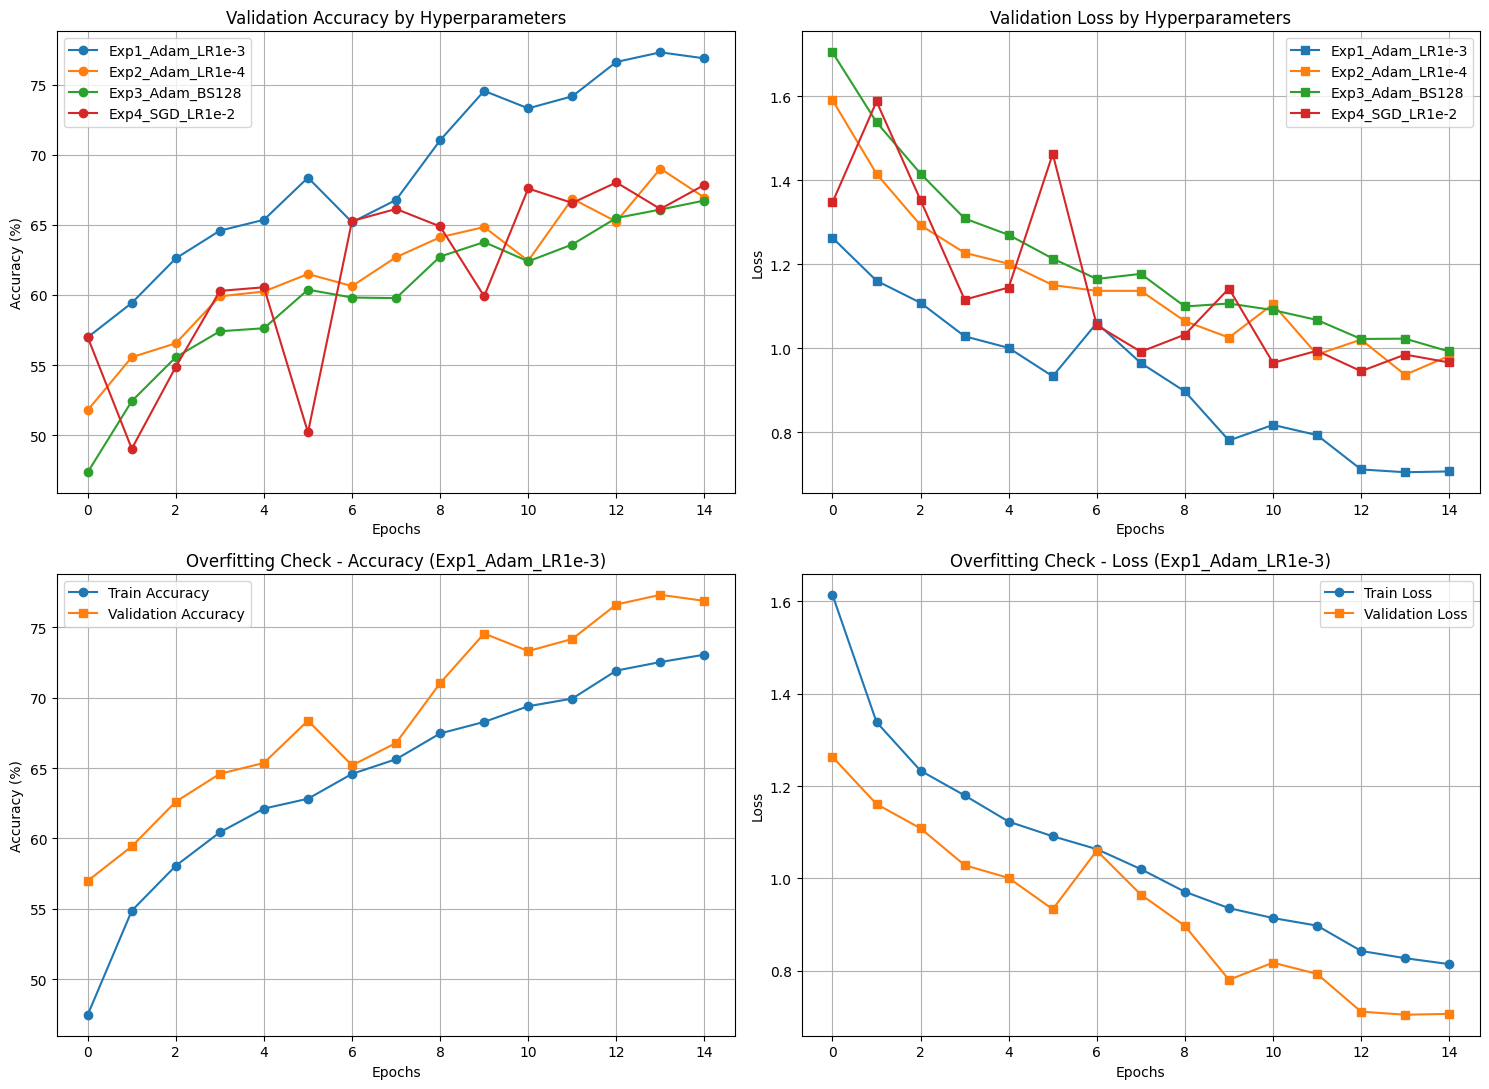


최종 선정 모델 (Exp1_Adam_LR1e-3) Test 평가 결과:
              precision    recall  f1-score   support

     battery       0.79      0.58      0.67       166
  biological       0.85      0.72      0.78       125
 brown-glass       0.68      0.84      0.75        95
   cardboard       0.79      0.76      0.78       121
     clothes       0.88      0.95      0.92       794
 green-glass       0.88      0.87      0.87       119
       metal       0.48      0.50      0.49       110
       paper       0.71      0.78      0.74       160
     plastic       0.48      0.57      0.52       120
       shoes       0.69      0.62      0.65       305
       trash       0.68      0.50      0.57       109
 white-glass       0.54      0.58      0.56       104

    accuracy                           0.76      2328
   macro avg       0.70      0.69      0.69      2328
weighted avg       0.76      0.76      0.76      2328



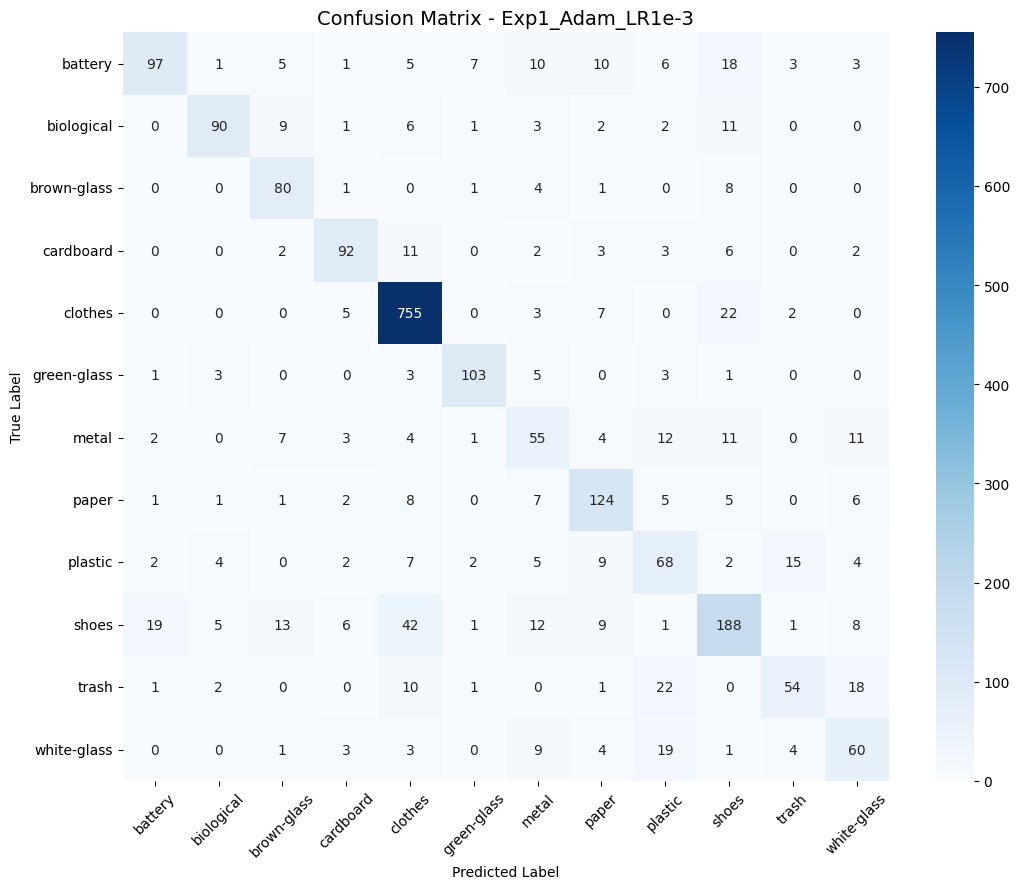

In [ ]:
best_exp_name = summary_df.sort_values(by="최고 검증 정확도(%)", ascending=False).iloc[0]["실험명"]
best_model = models_dict[best_exp_name]
best_hist = results[best_exp_name]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for name, hist in results.items():
    axes[0, 0].plot(hist['val_acc'], marker='o', label=name)
axes[0, 0].set_title("Validation Accuracy by Hyperparameters")
axes[0, 0].set_xlabel("Epochs")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].legend()
axes[0, 0].grid(True)

for name, hist in results.items():
    axes[0, 1].plot(hist['val_loss'], marker='s', label=name)
axes[0, 1].set_title("Validation Loss by Hyperparameters")
axes[0, 1].set_xlabel("Epochs")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[1, 0].plot(best_hist['train_acc'], marker='o', label='Train Accuracy')
axes[1, 0].plot(best_hist['val_acc'], marker='s', label='Validation Accuracy')
axes[1, 0].set_title(f"Overfitting Check - Accuracy ({best_exp_name})")
axes[1, 0].set_xlabel("Epochs")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(best_hist['train_loss'], marker='o', label='Train Loss')
axes[1, 1].plot(best_hist['val_loss'], marker='s', label='Validation Loss')
axes[1, 1].set_title(f"Overfitting Check - Loss ({best_exp_name})")
axes[1, 1].set_xlabel("Epochs")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Test 데이터셋 최종 평가 및 혼동 행렬
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
best_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = best_model(images)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print(f"\n최종 선정 모델 ({best_exp_name}) Test 평가 결과:")
print(classification_report(all_labels, all_preds, target_names=full_dataset.classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=full_dataset.classes, yticklabels=full_dataset.classes)
plt.title(f"Confusion Matrix - {best_exp_name}", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

7.추가 데이터셋(TrashNet) 결합 및 재학습

In [ ]:
extra_path = kagglehub.dataset_download("feyzazkefe/trashnet")
EXTRA_DIR = os.path.join(extra_path, "dataset-resized")
if not os.path.exists(EXTRA_DIR):
    for root, dirs, files in os.walk(extra_path):
        if "cardboard" in dirs and "plastic" in dirs:
            EXTRA_DIR = root
            break

class_to_idx = full_dataset.class_to_idx
valid_extra_classes = ['cardboard', 'metal', 'paper', 'plastic', 'trash']

class ExtraGarbageDataset(Dataset):
    def __init__(self, root_dir, class_to_idx, valid_classes, transform=None):
        self.samples = []
        self.transform = transform
        for cls_name in valid_classes:
            cls_folder = os.path.join(root_dir, cls_name)
            if os.path.exists(cls_folder):
                target_idx = class_to_idx[cls_name]
                for fname in os.listdir(cls_folder):
                    if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                        self.samples.append((os.path.join(cls_folder, fname), target_idx))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

extra_train_dataset = ExtraGarbageDataset(EXTRA_DIR, class_to_idx, valid_extra_classes, transform=fast_train_transform)
combined_train_dataset = ConcatDataset([train_dataset, extra_train_dataset])
print(f"병합 후 총 학습 데이터 수: {len(train_dataset)}장 -> {len(combined_train_dataset)}장")

best_config = [exp for exp in experiments if exp['name'] == best_exp_name][0].copy()
combined_train_loader = DataLoader(combined_train_dataset, batch_size=best_config['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=best_config['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

extra_model = get_model(num_classes, dropout_rate=best_config['dropout'])
criterion = nn.CrossEntropyLoss()

if best_config['optimizer'] == 'Adam':
    optimizer = optim.Adam(extra_model.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])
else:
    optimizer = optim.SGD(extra_model.parameters(), lr=best_config['lr'], momentum=0.9, weight_decay=best_config['weight_decay'])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)
scaler = torch.amp.GradScaler('cuda')

best_extra_val_acc = 0.0
best_extra_wts = copy.deepcopy(extra_model.state_dict())

epochs_extra = 15
for epoch in range(epochs_extra):
    extra_model.train()
    train_correct, train_total = 0, 0
    for images, labels in combined_train_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            outputs = extra_model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    extra_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = extra_model(images)
                loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = 100. * val_correct / val_total
    scheduler.step(val_loss)

    if val_acc > best_extra_val_acc:
        best_extra_val_acc = val_acc
        best_extra_wts = copy.deepcopy(extra_model.state_dict())

    print(f"[추가데이터 적용] Epoch {epoch+1}/{epochs_extra} | Train Acc: {100.*train_correct/train_total:.2f}% | Val Acc: {val_acc:.2f}%")

extra_model.load_state_dict(best_extra_wts)

Using Colab cache for faster access to the 'trashnet' dataset.
병합 후 총 학습 데이터 수: 10860장 -> 12886장
[추가데이터 적용] Epoch 1/15 | Train Acc: 46.31% | Val Acc: 58.70%
[추가데이터 적용] Epoch 2/15 | Train Acc: 54.24% | Val Acc: 57.16%
[추가데이터 적용] Epoch 3/15 | Train Acc: 57.81% | Val Acc: 55.44%
[추가데이터 적용] Epoch 4/15 | Train Acc: 62.10% | Val Acc: 63.94%
[추가데이터 적용] Epoch 5/15 | Train Acc: 63.16% | Val Acc: 61.97%
[추가데이터 적용] Epoch 6/15 | Train Acc: 64.22% | Val Acc: 68.63%
[추가데이터 적용] Epoch 7/15 | Train Acc: 65.02% | Val Acc: 70.39%
[추가데이터 적용] Epoch 8/15 | Train Acc: 65.64% | Val Acc: 56.60%
[추가데이터 적용] Epoch 9/15 | Train Acc: 66.54% | Val Acc: 71.81%
[추가데이터 적용] Epoch 10/15 | Train Acc: 67.72% | Val Acc: 71.51%
[추가데이터 적용] Epoch 11/15 | Train Acc: 67.95% | Val Acc: 72.45%
[추가데이터 적용] Epoch 12/15 | Train Acc: 68.62% | Val Acc: 69.88%
[추가데이터 적용] Epoch 13/15 | Train Acc: 69.96% | Val Acc: 73.18%
[추가데이터 적용] Epoch 14/15 | Train Acc: 70.25% | Val Acc: 73.79%
[추가데이터 적용] Epoch 15/15 | Train Acc: 70.88% | Val Acc: 71.6

<All keys matched successfully>

8.추가 데이터 적용 전/후 상세 비교 표 및 시각화 그래프

,구분,학습 데이터 수,Test 정확도(%)
0,기본 데이터셋만 사용 (Baseline),10860,75.86
1,추가 데이터셋 결합 (TrashNet 추가),12886,73.97


,클래스명,추가 데이터 보충 여부,기본 모델 F1(%),추가데이터 모델 F1(%),변화량(%p)
0,battery,X,67.13,60.70,-6.43
1,biological,X,77.59,69.54,-8.05
2,brown-glass,X,75.12,71.25,-3.87
3,cardboard,O (보충됨),78.15,78.40,+0.25
4,clothes,X,91.56,88.90,-2.66
5,green-glass,X,87.29,87.20,-0.09
6,metal,O (보충됨),48.89,58.18,+9.29
7,paper,O (보충됨),74.47,66.30,-8.17
8,plastic,O (보충됨),52.11,53.91,+1.80
9,shoes,X,64.94,64.11,-0.83


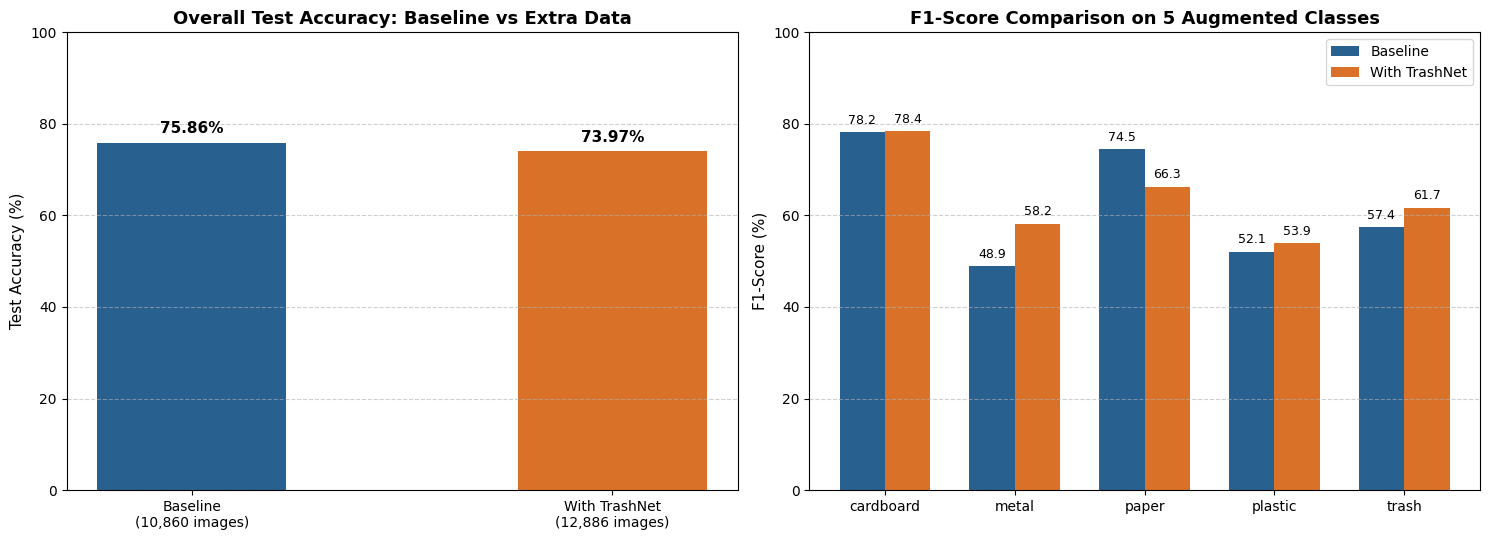

In [12]:
from sklearn.metrics import accuracy_score, f1_score

def get_predictions(model):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = model(images)
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred_base = get_predictions(best_model)
_, y_pred_extra = get_predictions(extra_model)

base_test_acc = accuracy_score(y_true, y_pred_base) * 100
extra_test_acc = accuracy_score(y_true, y_pred_extra) * 100

f1_base = f1_score(y_true, y_pred_base, average=None)
f1_extra = f1_score(y_true, y_pred_extra, average=None)

# 1. 전체 성능 비교 표
overall_df = pd.DataFrame({
    "구분": ["기본 데이터셋만 사용 (Baseline)", "추가 데이터셋 결합 (TrashNet 추가)"],
    "학습 데이터 수": [len(train_dataset), len(combined_train_dataset)],
    "Test 정확도(%)": [round(base_test_acc, 2), round(extra_test_acc, 2)]
})
display(overall_df)

# 2. 클래스별 F1-Score 비교 표
class_comp_list = []
for idx, cls_name in enumerate(class_names):
    is_aug = "O (보충됨)" if cls_name in valid_extra_classes else "X"
    b_f1 = round(f1_base[idx] * 100, 2)
    e_f1 = round(f1_extra[idx] * 100, 2)
    diff = round(e_f1 - b_f1, 2)
    class_comp_list.append({
        "클래스명": cls_name,
        "추가 데이터 보충 여부": is_aug,
        "기본 모델 F1(%)": b_f1,
        "추가데이터 모델 F1(%)": e_f1,
        "변화량(%p)": f"{diff:+.2f}"
    })
class_comp_df = pd.DataFrame(class_comp_list)
display(class_comp_df)

# 3. 비교 막대그래프 시각화 (y축 0~100% 수정)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

labels_acc = [f'Baseline\n({len(train_dataset):,} images)', f'With TrashNet\n({len(combined_train_dataset):,} images)']
acc_values = [base_test_acc, extra_test_acc]
bars0 = axes[0].bar(labels_acc, acc_values, color=['#286090', '#d97228'], width=0.45)
axes[0].set_title('Overall Test Accuracy: Baseline vs Extra Data', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Test Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 100)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars0:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

x = np.arange(len(valid_extra_classes))
width = 0.35
base_f1_5 = [f1_base[class_names.index(c)] * 100 for c in valid_extra_classes]
extra_f1_5 = [f1_extra[class_names.index(c)] * 100 for c in valid_extra_classes]

rects1 = axes[1].bar(x - width/2, base_f1_5, width, label='Baseline', color='#286090')
rects2 = axes[1].bar(x + width/2, extra_f1_5, width, label='With TrashNet', color='#d97228')

axes[1].set_title('F1-Score Comparison on 5 Augmented Classes', fontsize=13, fontweight='bold')
axes[1].set_ylabel('F1-Score (%)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(valid_extra_classes, fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2, h + 1.2, f'{h:.1f}', ha='center', va='bottom', fontsize=9)
for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2, h + 1.2, f'{h:.1f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()